# Влияние параметра C в SVC

В этой работе проверяется, как параметр `C` влияет на классификацию автомобилей.

## 1. Загрузка данных

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

RANDOM_STATE = 42
data_path = Path("car_dataset.csv")
if not data_path.exists():
    data_path = Path("src") / "car_dataset.csv"
if not data_path.exists():
    raise FileNotFoundError("Не найден файл src/car_dataset.csv")

data = pd.read_csv(data_path)
target_column = "segment"
feature_columns = [column for column in data.columns if column != target_column]
X = data[feature_columns]
y = data[target_column]

print(f"Размер данных: {data.shape[0]} автомобилей")
print(f"Количество признаков: {len(feature_columns)}")
print(y.value_counts())

Размер данных: 1500 автомобилей
Количество признаков: 10
segment
sport     500
city      500
family    500
Name: count, dtype: int64


## 2. Разбиение данных и параметры

Маленькое значение `C` сильнее допускает ошибки на обучении. Большое значение `C` заставляет модель точнее разделять обучающие объекты, но может привести к переобучению.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

kernels = ["linear", "rbf", "poly", "sigmoid"]
c_values = 10.0 ** np.arange(-3, 4)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "f1_macro": "f1_macro",
}

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

Обучающая выборка: (1125, 10)
Тестовая выборка: (375, 10)


## 3. Перебор C и ядер

In [3]:
rows = []
for kernel in kernels:
    for c_value in c_values:
        model = Pipeline(
            [
                ("scaler", StandardScaler()),
                ("svc", SVC(C=c_value, kernel=kernel, gamma="scale", degree=3)),
            ]
        )
        started = time.perf_counter()
        scores = cross_validate(
            model,
            X_train,
            y_train,
            cv=cv,
            scoring=scoring,
            n_jobs=1,
            return_train_score=True,
        )
        rows.append(
            {
                "kernel": kernel,
                "C": c_value,
                "accuracy": scores["test_accuracy"].mean(),
                "accuracy_std": scores["test_accuracy"].std(ddof=1),
                "balanced_accuracy": scores["test_balanced_accuracy"].mean(),
                "balanced_accuracy_std": scores["test_balanced_accuracy"].std(ddof=1),
                "f1_macro": scores["test_f1_macro"].mean(),
                "f1_macro_std": scores["test_f1_macro"].std(ddof=1),
                "train_accuracy": scores["train_accuracy"].mean(),
                "fit_time": scores["fit_time"].mean(),
                "elapsed_time": time.perf_counter() - started,
            }
        )

results = pd.DataFrame(rows)
results.sort_values("balanced_accuracy", ascending=False).head(10)

,kernel,C,accuracy,accuracy_std,balanced_accuracy,balanced_accuracy_std,f1_macro,f1_macro_std,train_accuracy,fit_time,elapsed_time
10,rbf,1.000,0.899556,0.016510,0.899556,0.016510,0.899417,0.016755,0.935333,0.008837,0.177068
9,rbf,0.100,0.896000,0.015587,0.896000,0.015587,0.895979,0.015743,0.903333,0.011586,0.249034
8,rbf,0.010,0.886222,0.019525,0.886222,0.019525,0.885763,0.020369,0.893333,0.019729,0.349456
7,rbf,0.001,0.886222,0.019525,0.886222,0.019525,0.885763,0.020369,0.893333,0.021238,0.359644
1,linear,0.010,0.884444,0.014055,0.884444,0.014055,0.884588,0.014014,0.891333,0.007952,0.124126
22,sigmoid,0.010,0.884444,0.012172,0.884444,0.012172,0.884711,0.012137,0.879333,0.021396,0.258800
2,linear,0.100,0.883556,0.021175,0.883556,0.021175,0.883464,0.021451,0.893333,0.007584,0.112636
11,rbf,10.000,0.882667,0.012008,0.882667,0.012008,0.882774,0.011919,0.980444,0.010140,0.171519
23,sigmoid,0.100,0.880889,0.016147,0.880889,0.016147,0.880881,0.016324,0.882222,0.013360,0.199769
0,linear,0.001,0.880000,0.011331,0.880000,0.011331,0.880746,0.011556,0.882222,0.014509,0.186204


## 4. Сводка по ядрам

In [4]:
best_by_kernel = (
    results.sort_values("balanced_accuracy", ascending=False)
    .groupby("kernel", as_index=False)
    .first()
    [["kernel", "C", "balanced_accuracy", "balanced_accuracy_std", "accuracy", "accuracy_std", "fit_time"]]
)
best_by_kernel

,kernel,C,balanced_accuracy,balanced_accuracy_std,accuracy,accuracy_std,fit_time
0,linear,0.01,0.884444,0.014055,0.884444,0.014055,0.007952
1,poly,1.00,0.852444,0.014538,0.852444,0.014538,0.009470
2,rbf,1.00,0.899556,0.016510,0.899556,0.016510,0.008837
3,sigmoid,0.01,0.884444,0.012172,0.884444,0.012172,0.021396


## 5. Графики

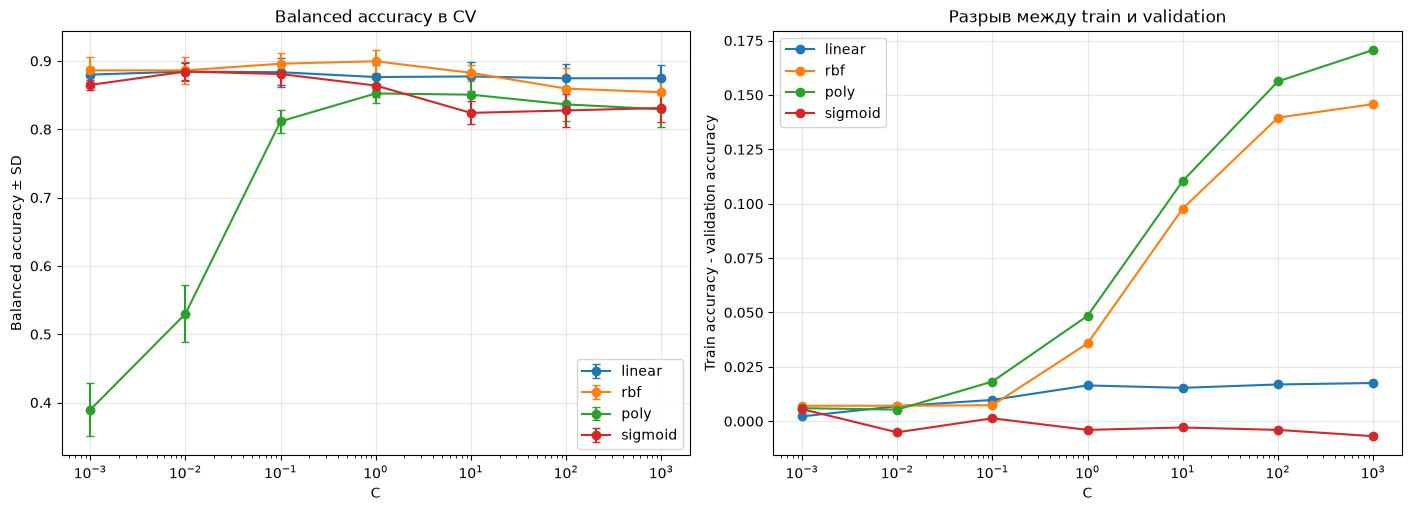

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for kernel in kernels:
    part = results[results["kernel"] == kernel]
    axes[0].errorbar(part["C"], part["balanced_accuracy"], yerr=part["balanced_accuracy_std"], marker="o", capsize=3, label=kernel)
    gap = part["train_accuracy"] - part["accuracy"]
    axes[1].plot(part["C"], gap, marker="o", label=kernel)

for axis in axes:
    axis.set_xscale("log")
    axis.set_xlabel("C")
    axis.grid(alpha=0.3)
    axis.legend()

axes[0].set_title("Balanced accuracy в CV")
axes[0].set_ylabel("Balanced accuracy ± SD")
axes[1].set_title("Разрыв между train и validation")
axes[1].set_ylabel("Train accuracy - validation accuracy")
plt.show()

## 6. Проверка лучшей модели на тесте

In [6]:
best_row = results.loc[results["balanced_accuracy"].idxmax()]
best_model = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("svc", SVC(C=float(best_row["C"]), kernel=best_row["kernel"], gamma="scale", degree=3)),
    ]
)
best_model.fit(X_train, y_train)
test_prediction = best_model.predict(X_test)

print(f"Лучшее ядро: {best_row['kernel']}")
print(f"Лучшее C: {best_row['C']}")
print(f"Test accuracy: {accuracy_score(y_test, test_prediction):.4f}")
print(f"Test balanced accuracy: {balanced_accuracy_score(y_test, test_prediction):.4f}")
print(f"Test F1 macro: {f1_score(y_test, test_prediction, average='macro'):.4f}")
print("Параметры SVC: gamma='scale', degree=3")

Лучшее ядро: rbf
Лучшее C: 1.0
Test accuracy: 0.9173
Test balanced accuracy: 0.9173
Test F1 macro: 0.9168
Параметры SVC: gamma='scale', degree=3


## Вывод

- У RBF-ядра качество сначала растёт при увеличении `C`, а затем может снижаться, тогда как train accuracy приближается к 1. Это похоже на переобучение.
- У линейного ядра качество обычно меняется слабее. Большие значения `C` могут заметно увеличить время обучения без заметного выигрыша.
- У полиномиального ядра малые значения `C` могут давать слабое качество, а у sigmoid есть свой оптимум, после которого качество не обязательно растёт.
- Если соседние малые значения `C` дают одинаковые метрики, это означает, что модель находится в режиме сильной регуляризации и её предсказания пока не меняются.
- Классы в датасете сбалансированы, поэтому accuracy и balanced accuracy почти совпадают. Для сравнения важнее смотреть не только на среднее, но и на стандартное отклонение по фолдам.
- Результаты относятся к этому синтетическому датасету и фиксированным `gamma='scale'` и `degree=3`. Для RBF изменение `gamma` вместе с `C` могло бы дать другой результат.